# Neuromodulation and collective locomotion in modWorm

Reproducible experiments using the repository's 279-neuron network, muscle map, body mechanics, and shared-world solver. Run from top to bottom. `QUICK_MODE=True` uses the first six samples of the repository's gentle-touch stimulus; set it to `False` for a longer 1 s run. Connectome workbook loading is performed in both modes.

Serotonin is an explicit MOD-1 intervention. PDF-1 uses the module's abstract receptor/cAMP-like state and optional excitability bias; this downstream mapping is a hypothesis, not a calibrated receptor current. The contact-to-touch-cell map and gain are also approximations. No collision-triggered reversal or turn is imposed. Outputs are computed by simulation, not supplied trajectories.

In [1]:
from pathlib import Path
import json
import time
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import expit

ROOT = Path.cwd().resolve()
if not (ROOT / 'modWorm').is_dir():
    ROOT = next((p for p in (ROOT.parent, *ROOT.parents) if (p / 'modWorm').is_dir()), ROOT)
if not (ROOT / 'modWorm').is_dir():
    raise FileNotFoundError('Run this notebook from the modWorm repository.')
import os, sys
os.chdir(ROOT)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from modWorm import utils
from modWorm.predefined_classes_nv import CelegansWorm_NervousSystem
from modWorm.predefined_classes_mb import CelegansWorm_MuscleBody
from modWorm.shared_world import WormAgent, run_single_worm, run_two_worms
from modWorm.serotonin import NEURON_INDICES, SerotoninModulation
from modWorm.pdf_modulation import PDFR1Modulation

QUICK_MODE = True
SEED = 20261014
MAX_STEPS = 6 if QUICK_MODE else 101
DT = 0.01
gap_connectome, chemical_connectome = utils.construct_connectome_Varshney(str(ROOT / 'database' / 'NeuronConnect.xls'))
muscle_map = utils.construct_muscle_map_Hall(str(ROOT / 'database' / 'NeuronFixedPoints.xls'))
touch_input = np.load(ROOT / 'modWorm' / 'presets_input' / 'input_mat_gentle_post_touch.npy')
if gap_connectome.shape != (279, 279) or chemical_connectome.shape != (279, 279) or muscle_map.shape != (96, 279):
    raise ValueError('Unexpected local connectome or muscle-map dimensions.')
n_steps = min(MAX_STEPS, len(touch_input))
times = DT * np.arange(n_steps, dtype=float)
stimulus = np.asarray(touch_input[:n_steps], dtype=float)
rng = np.random.default_rng(SEED)
initial_neural_state = np.concatenate((rng.normal(0, 1e-4, 279), rng.normal(0, 1e-4, 279)))
mean_radius = float(np.mean(CelegansWorm_MuscleBody(muscle_map).body_RadiusH))
CONTACT_OFFSET = 1.5 * mean_radius

def make_agent(name, *, y_offset=0.0, serotonin=0.0, pdf=0.0, pdf_gain=0.0):
    network = CelegansWorm_NervousSystem(gap_connectome, chemical_connectome)
    network.initcond = initial_neural_state.copy()
    network.serotonin_modulation = SerotoninModulation(concentration=serotonin)
    network.pdfr1_modulation = PDFR1Modulation(
        concentration=pdf,
        coupling_gain_pA_per_signal=pdf_gain,
        target_neurons=('AIYL', 'AIYR', 'RIML', 'RIMR', 'RIAL', 'RIAR'),
    )
    body = CelegansWorm_MuscleBody(muscle_map)
    body.initcond[1] += y_offset
    return WormAgent(network, body, stimulus.copy(), name)

def centerline_position(result):
    return np.column_stack((result['x_solution'].mean(axis=1), result['y_solution'].mean(axis=1)))

def mean_speed(result):
    position = centerline_position(result)
    return float(np.mean(np.linalg.norm(np.diff(position, axis=0), axis=1) / np.diff(result['time'])))

print(f'Mode={"quick" if QUICK_MODE else "research"}; samples={n_steps}; duration={times[-1]:.3f} s')
print(f'Connectome nonzeros: gap={np.count_nonzero(gap_connectome)}, chemical={np.count_nonzero(chemical_connectome)}; muscle map={muscle_map.shape}')
print(f'Exploratory contact centerline offset={CONTACT_OFFSET:.6g}; mean body radius={mean_radius:.6g}')

Mode=quick; samples=6; duration=0.050 s
Connectome nonzeros: gap=1122, chemical=2305; muscle map=(96, 279)
Exploratory contact centerline offset=0.4875; mean body radius=0.325


## 1. Baseline single-worm neural, muscle, and body locomotion

This baseline uses the full local Varshney connectome, gentle-touch input, mapped muscles, and original body equations. The shared-world runner is used with one agent so all samples pass the same numerical validation as paired runs.

Baseline completed in 6.100 s; neural shape=(6, 279); muscle shape=(6, 48); body shape=(6, 52)
Measured mean centerline speed=0.0124681; body solver evaluations=880


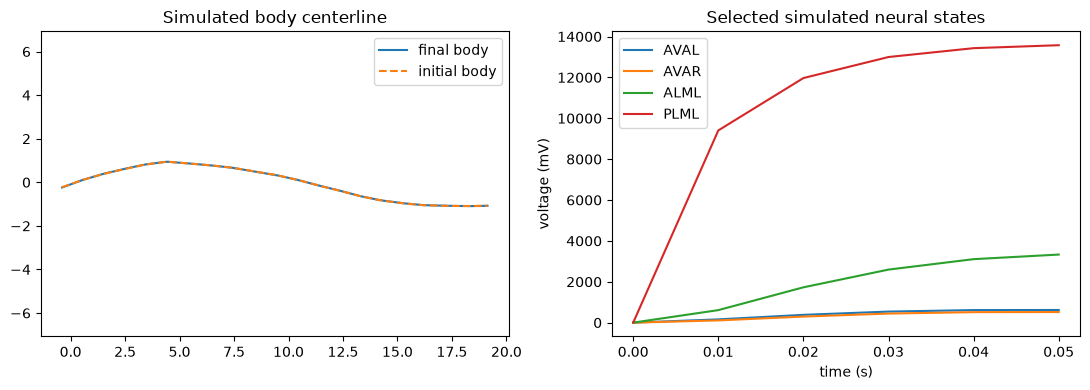

In [2]:
baseline_start = time.perf_counter()
baseline_world = run_single_worm(make_agent('baseline'), times, mechanical_contact=False, sensory_contact=False)
baseline = baseline_world['agents'][0]
print(f"Baseline completed in {time.perf_counter() - baseline_start:.3f} s; neural shape={baseline['v_solution'].shape}; muscle shape={baseline['muscle_force'].shape}; body shape={baseline['body_state'].shape}")
print(f"Measured mean centerline speed={mean_speed(baseline):.6g}; body solver evaluations={baseline_world['solver']['body_nfev']}")
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(baseline['x_solution'][-1], baseline['y_solution'][-1], label='final body')
axes[0].plot(baseline['x_solution'][0], baseline['y_solution'][0], '--', label='initial body')
axes[0].set_aspect('equal', adjustable='datalim'); axes[0].set_title('Simulated body centerline'); axes[0].legend()
for name in ('AVAL', 'AVAR', 'ALML', 'PLML'):
    index = NEURON_INDICES[name]
    axes[1].plot(times, baseline['v_solution'][:, index], label=name)
axes[1].set(xlabel='time (s)', ylabel='voltage (mV)', title='Selected simulated neural states'); axes[1].legend()
plt.tight_layout()

## 2. Controlled serotonin interventions

Compare 0 μM, constant 5 μM, and a time-varying concentration control under identical initial neural states and sensory input. The model's serotonin implementation is the existing MOD-1 current on its configured targets.

0 uM: mean AIY voltage=63.4793; mean speed=0.0124681
5 uM constant: mean AIY voltage=-46.8162; mean speed=0.0101794
0-5 uM ramp: mean AIY voltage=-45.1983; mean speed=0.0128163


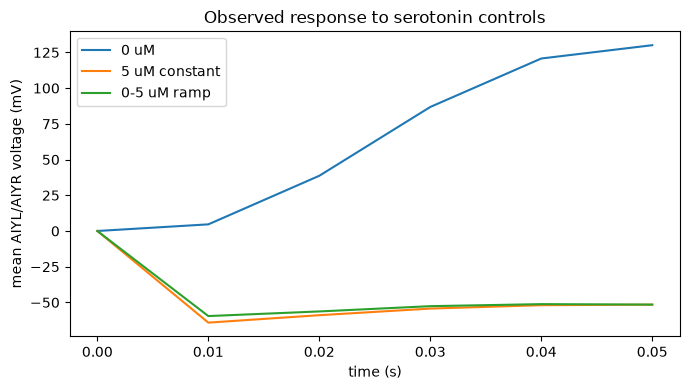

In [3]:
serotonin_results = {}
serotonin_controls = {
    '0 uM': 0.0,
    '5 uM constant': 5.0,
    '0-5 uM ramp': lambda t: 5.0 * min(max(t / max(times[-1], DT), 0.0), 1.0),
}
for label, control in serotonin_controls.items():
    serotonin_results[label] = run_single_worm(
        make_agent(label, serotonin=control), times,
        mechanical_contact=False, sensory_contact=False,
    )['agents'][0]
aiy = [NEURON_INDICES['AIYL'], NEURON_INDICES['AIYR']]
for label, result in serotonin_results.items():
    print(f'{label}: mean AIY voltage={result["v_solution"][:, aiy].mean():.6g}; mean speed={mean_speed(result):.6g}')
plt.figure(figsize=(7, 4))
for label, result in serotonin_results.items():
    plt.plot(times, result['v_solution'][:, aiy].mean(axis=1), label=label)
plt.xlabel('time (s)'); plt.ylabel('mean AIYL/AIYR voltage (mV)'); plt.legend(); plt.title('Observed response to serotonin controls'); plt.tight_layout()

## 3. PDF-1 signaling and downstream hypothesis

PDFR-1 receptor occupancy and a slow cAMP-like state are integrated with the shared simulation clock. The optional current is a zero-default, explicitly parameterized excitability-bias hypothesis on named targets; it is not established cell-specific PDF-1 physiology. Compare signaling state and measured AIY/RIM voltage without interpreting a predetermined behavioral direction.

PDFR-1/cAMP-like state shape: (6, 6)
Final abstract signal state: [0.00829181 0.00829181 0.00829181 0.00829181 0.00829181 0.00829181]
Mean target voltage, no PDF: 67.21187595583437
Mean target voltage, PDF hypothesis enabled: 67.22778251597131


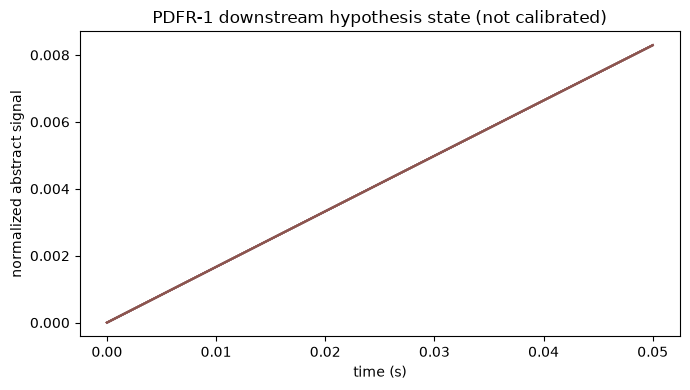

In [4]:
pdf_control = run_single_worm(
    make_agent('PDF-1 intervention', pdf=5.0, pdf_gain=1.0), times,
    mechanical_contact=False, sensory_contact=False,
)['agents'][0]
pdf_targets = [NEURON_INDICES[name] for name in ('AIYL', 'AIYR', 'RIML', 'RIMR', 'RIAL', 'RIAR')]
print('PDFR-1/cAMP-like state shape:', pdf_control['pdf_signal_solution'].shape)
print('Final abstract signal state:', pdf_control['pdf_signal_solution'][-1])
print('Mean target voltage, no PDF:', baseline['v_solution'][:, pdf_targets].mean())
print('Mean target voltage, PDF hypothesis enabled:', pdf_control['v_solution'][:, pdf_targets].mean())
plt.figure(figsize=(7, 4))
plt.plot(times, pdf_control['pdf_signal_solution'])
plt.xlabel('time (s)'); plt.ylabel('normalized abstract signal'); plt.title('PDFR-1 downstream hypothesis state (not calibrated)'); plt.tight_layout()

## 4. Two independent worms in one world

Each animal has its own neural model, body, initial state, neuromodulator configuration, and solver history. Both are advanced on the same clock, with both coupling pathways disabled.

In [5]:
independent_world = run_two_worms(
    make_agent('independent A'), make_agent('independent B', y_offset=CONTACT_OFFSET), times,
    mechanical_contact=False, sensory_contact=False,
)
for result in independent_world['agents']:
    print(f"{result['name']}: speed={mean_speed(result):.6g}; final position={centerline_position(result)[-1]}; max contact force={np.linalg.norm(result['contact_force'], axis=2).max():.6g}")

independent A: speed=0.0124681; final position=[10.92158801 -0.20792651]; max contact force=0
independent B: speed=0.0124681; final position=[10.92158801  0.27957349]; max contact force=0


## 5. Two worms with mechanical contact

Capsule forces are recomputed inside the coupled body ODE and enter the original nodal-force pathway. No trajectories are edited after integration. Force parameters and initial separation are exposed experimental assumptions.

mechanical A: peak nodal contact force=0.173676; speed=0.012603
mechanical B: peak nodal contact force=0.173534; speed=0.0123343
mechanical A: final body-state difference vs independent=0.0169844
mechanical B: final body-state difference vs independent=0.0225282


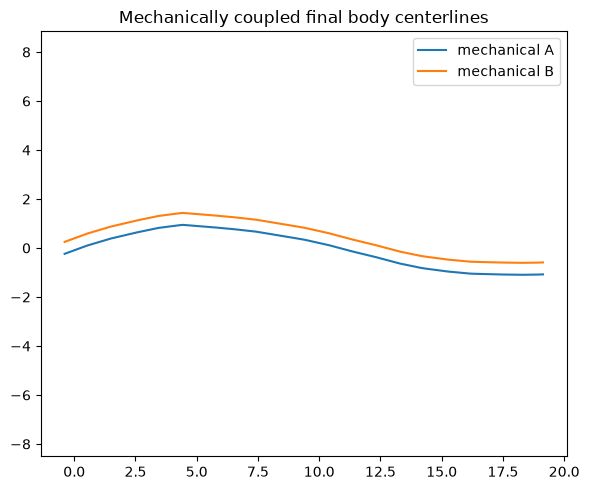

In [6]:
contact_parameters = dict(contact_radii=(mean_radius, mean_radius), contact_stiffness=0.2)
mechanical_world = run_two_worms(
    make_agent('mechanical A'), make_agent('mechanical B', y_offset=CONTACT_OFFSET), times,
    mechanical_contact=True, sensory_contact=False, **contact_parameters,
)
for result in mechanical_world['agents']:
    print(f"{result['name']}: peak nodal contact force={np.linalg.norm(result['contact_force'], axis=2).max():.6g}; speed={mean_speed(result):.6g}")
for free, coupled in zip(independent_world['agents'], mechanical_world['agents']):
    body_delta = np.linalg.norm(coupled['body_state'][-1] - free['body_state'][-1])
    print(f"{coupled['name']}: final body-state difference vs independent={body_delta:.6g}")
fig, ax = plt.subplots(figsize=(6, 5))
for result in mechanical_world['agents']:
    ax.plot(result['x_solution'][-1], result['y_solution'][-1], label=result['name'])
ax.set_aspect('equal', adjustable='datalim'); ax.set_title('Mechanically coupled final body centerlines'); ax.legend(); plt.tight_layout()

## 6. Mechanical and mechanosensory coupling

This run retains body contact and separately enables the configurable touch-cell current proxy. Compare with the mechanical-only condition above; report observed touch-cell and downstream command-neuron voltage changes rather than assuming a reversal or turn.

mechanosensory A: peak sensory current=0.164079; peak contact force=0.173544
  ALML: maximum voltage difference vs mechanical-only = 1.23807 mV
  ALMR: maximum voltage difference vs mechanical-only = 1.81153 mV
  AVM: maximum voltage difference vs mechanical-only = 1.05121 mV
  PVM: maximum voltage difference vs mechanical-only = 0.559432 mV
  PLML: maximum voltage difference vs mechanical-only = 0.691784 mV
  PLMR: maximum voltage difference vs mechanical-only = 0.735127 mV
  AVAL: maximum voltage difference vs mechanical-only = 0.0409099 mV
  AVAR: maximum voltage difference vs mechanical-only = 0.0339613 mV
  AVBL: maximum voltage difference vs mechanical-only = 0.0311878 mV
  AVBR: maximum voltage difference vs mechanical-only = 0.0322243 mV
mechanosensory B: peak sensory current=0.163846; peak contact force=0.17351
  ALML: maximum voltage difference vs mechanical-only = 1.24972 mV
  ALMR: maximum voltage difference vs mechanical-only = 1.81196 mV
  AVM: maximum voltage difference 

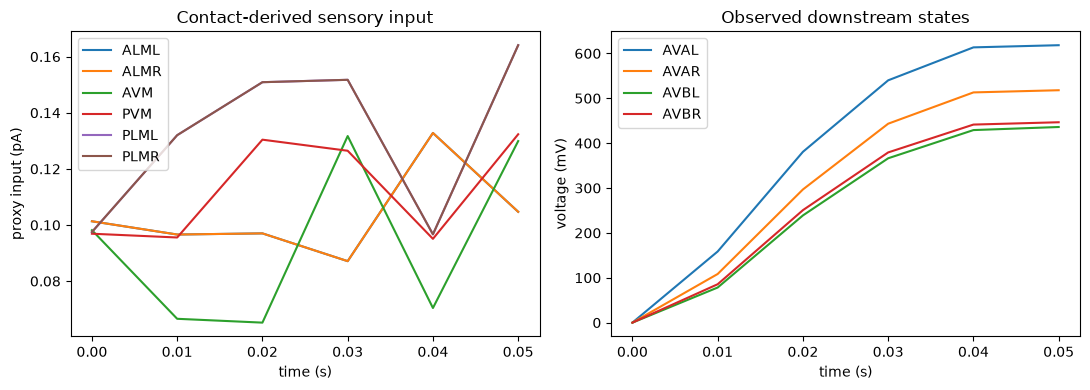

In [7]:
sensory_world = run_two_worms(
    make_agent('mechanosensory A'), make_agent('mechanosensory B', y_offset=CONTACT_OFFSET), times,
    mechanical_contact=True, sensory_contact=True,
    sensory_gain_pA_per_force=1.0, **contact_parameters,
)
touch_names = ('ALML', 'ALMR', 'AVM', 'PVM', 'PLML', 'PLMR')
downstream_names = ('AVAL', 'AVAR', 'AVBL', 'AVBR')
for mechanical, combined in zip(mechanical_world['agents'], sensory_world['agents']):
    print(f"{combined['name']}: peak sensory current={combined['contact_sensory_current'].max():.6g}; peak contact force={np.linalg.norm(combined['contact_force'], axis=2).max():.6g}")
    for name in touch_names + downstream_names:
        index = NEURON_INDICES[name]
        delta = np.max(np.abs(combined['v_solution'][:, index] - mechanical['v_solution'][:, index]))
        print(f'  {name}: maximum voltage difference vs mechanical-only = {delta:.6g} mV')

first = sensory_world['agents'][0]
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for name in touch_names:
    axes[0].plot(times, first['contact_sensory_current'][:, NEURON_INDICES[name]], label=name)
for name in downstream_names:
    axes[1].plot(times, first['v_solution'][:, NEURON_INDICES[name]], label=name)
axes[0].set(xlabel='time (s)', ylabel='proxy input (pA)', title='Contact-derived sensory input'); axes[0].legend()
axes[1].set(xlabel='time (s)', ylabel='voltage (mV)', title='Observed downstream states'); axes[1].legend()
plt.tight_layout()

## 7. Quantitative comparison of trajectories, neural activity, body motion, and contact

The table and plots below summarize arrays returned by the solver. These short runs establish execution and measurable differences only; they do not establish persistent roaming/dwelling states, a calibrated receptor mechanism, or population-level collective behavior.

{'condition': 'baseline', 'mean_speed': 0.012468129056850102, 'path_length': 0.0006234064528425051, 'neural_voltage_rms': 1129.732275278311, 'muscle_force_rms': 5049.650995796544, 'peak_contact_force': 0.0, 'peak_sensory_current': 0.0}
{'condition': '0 uM', 'mean_speed': 0.012468129056850102, 'path_length': 0.0006234064528425051, 'neural_voltage_rms': 1129.732275278311, 'muscle_force_rms': 5049.650995796544, 'peak_contact_force': 0.0, 'peak_sensory_current': 0.0}
{'condition': '5 uM constant', 'mean_speed': 0.01017941084179643, 'path_length': 0.0005089705420898215, 'neural_voltage_rms': 1129.599693458162, 'muscle_force_rms': 5011.985859083605, 'peak_contact_force': 0.0, 'peak_sensory_current': 0.0}
{'condition': '0-5 uM ramp', 'mean_speed': 0.012816339270602991, 'path_length': 0.0006408169635301495, 'neural_voltage_rms': 1129.5949362062966, 'muscle_force_rms': 5024.70646581219, 'peak_contact_force': 0.0, 'peak_sensory_current': 0.0}
{'condition': 'independent A', 'mean_speed': 0.012468

All displayed neural, muscular, body, trajectory, and force quantities were produced by the executed modWorm simulations.


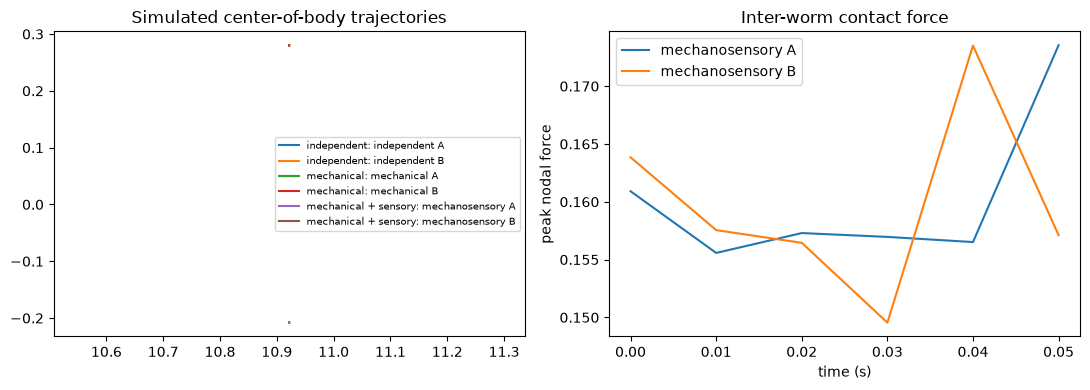

In [8]:
def summarize(label, result):
    return {
        'condition': label,
        'mean_speed': mean_speed(result),
        'path_length': float(np.linalg.norm(np.diff(centerline_position(result), axis=0), axis=1).sum()),
        'neural_voltage_rms': float(np.sqrt(np.mean(result['v_solution'] ** 2))),
        'muscle_force_rms': float(np.sqrt(np.mean(result['muscle_force'] ** 2))),
        'peak_contact_force': float(np.linalg.norm(result['contact_force'], axis=2).max()),
        'peak_sensory_current': float(result['contact_sensory_current'].max()),
    }
rows = [summarize('baseline', baseline)]
rows.extend(summarize(name, result) for name, result in serotonin_results.items())
rows.extend(summarize(result['name'], result) for result in independent_world['agents'])
rows.extend(summarize(result['name'], result) for result in mechanical_world['agents'])
rows.extend(summarize(result['name'], result) for result in sensory_world['agents'])
for row in rows:
    print(row)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for condition, results in (('independent', independent_world), ('mechanical', mechanical_world), ('mechanical + sensory', sensory_world)):
    for result in results['agents']:
        position = centerline_position(result)
        axes[0].plot(position[:, 0], position[:, 1], label=f'{condition}: {result["name"]}')
axes[0].set_aspect('equal', adjustable='datalim'); axes[0].set_title('Simulated center-of-body trajectories'); axes[0].legend(fontsize=7)
for result in sensory_world['agents']:
    axes[1].plot(times, np.linalg.norm(result['contact_force'], axis=2).max(axis=1), label=result['name'])
axes[1].set(xlabel='time (s)', ylabel='peak nodal force', title='Inter-worm contact force'); axes[1].legend()
plt.tight_layout()
print('All displayed neural, muscular, body, trajectory, and force quantities were produced by the executed modWorm simulations.')

## 8. Small-group proximity and clustering metrics

This is an observational geometry analysis of the two-worm trajectories, not an additional behavioral force or evidence for attraction. Its distance threshold is exposed and exploratory; contact-force data remain the mechanical measure.

In [9]:
from modWorm.behavior_analysis import population_metrics

cluster_distance = 2.0 * mean_radius
for label, world in (('independent', independent_world), ('mechanical', mechanical_world), ('mechanical + sensory', sensory_world)):
    positions = np.stack([centerline_position(result) for result in world['agents']], axis=1)
    metrics = population_metrics(times, positions, cluster_distance=cluster_distance)
    pair_distance = metrics['pairwise_distances'][:, 0, 1]
    print(f'{label}: cluster threshold={cluster_distance:.6g}; cluster counts={metrics["cluster_count"].tolist()}; mean pair distance={pair_distance.mean():.6g}; minimum pair distance={pair_distance.min():.6g}')
    if world['mechanical_contact']:
        peak = max(np.linalg.norm(result['contact_force'], axis=2).max() for result in world['agents'])
        print(f'  maximum mechanical contact force={peak:.6g}')

independent: cluster threshold=0.65; cluster counts=[1, 1, 1, 1, 1, 1]; mean pair distance=0.4875; minimum pair distance=0.4875
mechanical: cluster threshold=0.65; cluster counts=[1, 1, 1, 1, 1, 1]; mean pair distance=0.487675; minimum pair distance=0.487668
  maximum mechanical contact force=0.173676
mechanical + sensory: cluster threshold=0.65; cluster counts=[1, 1, 1, 1, 1, 1]; mean pair distance=0.487671; minimum pair distance=0.487664
  maximum mechanical contact force=0.173544
